# STRIDE explanation API: a minimal tour

One short example per explanation method in `stride.xai`, most on the same SEA stream:
a reference block of 1000 samples (SEA variant 0) and a detection block of 1000
samples (SEA variant 3).

Recurring-concept analysis needs many windows, so it uses
a multi-window RandomTree dataset.
The same dataset is used for drift detection.

| Section | Layer | API |
|---|---|---|
| 1 | Data | `DescriptiveStatisticsDriftDetector` |
| 2 | Data | `StatisticalTestsDriftDetector` |
| 3 | Data | `ClusterBasedDriftDetector` |
| 4 | Explanation | `DecisionBoundaryDriftAnalyzer` (SSNP + disagreement tree) |
| 5 | Explanation | `FeatureImportanceDriftAnalyzer` (PFI, SHAP, LIME, abstention) |
| 6 | Explanation | `FullWindowStorage` + `cluster_windows` (recurring concepts + prototypes) |
| 7 | Detection   | `generate_error_stream` + `run_drift_detection`|

Requires the full install: `pip install -e ".[all]"` (SHAP/LIME, HDBSCAN/X-Means, TensorFlow for SSNP).

## 0. Data: SEA, two blocks of 1000

In [19]:
import sys, numpy
print(sys.executable)
print(numpy.__version__, numpy.__file__)

/home/deniz/Desktop/szkola/inżynierka/DriftDetectionWithExplainableAI/.venv/bin/python
1.26.4 /home/deniz/Desktop/szkola/inżynierka/DriftDetectionWithExplainableAI/.venv/lib/python3.11/site-packages/numpy/__init__.py


In [20]:
import io
import os
import warnings

from contextlib import redirect_stderr, redirect_stdout
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # quiet TensorFlow C++ logs

import pandas as pd

from stride.datasets import SeaDriftDataset
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*(midrank|p-value capped).*")  # SciPy anderson_ksamp notices
%matplotlib inline

BLOCK = 1000
SEED = 42

In [21]:

X, y = SeaDriftDataset().generate(n_samples_before=BLOCK, n_samples_after=BLOCK, random_seed=SEED)

# Reference (pre-drift) and detection (post-drift) blocks.
# reset_index: some detectors align X and y by index (see section 1).
X_ref, y_ref = X.iloc[:BLOCK].reset_index(drop=True), y.iloc[:BLOCK].reset_index(drop=True)
X_det, y_det = X.iloc[BLOCK:].reset_index(drop=True), y.iloc[BLOCK:].reset_index(drop=True)

print(X.shape, list(X.columns), "classes:", sorted(y.unique()))
X_ref.head()

(2000, 3) ['X1', 'X2', 'X3'] classes: [False, True]


,X1,X2,X3
0,6.394268,0.250108,2.750293
1,2.232107,7.364712,6.766995
2,8.921796,0.869388,4.219218
3,0.297972,2.186380,5.053553
4,0.265360,1.988377,6.498844


## 1. Descriptive statistics

Per-class relative shifts of mean, std, min, max, median and the class imbalance ratio.

In [22]:
from stride.xai.stats import DescriptiveStatisticsDriftDetector, StatisticsType

desc = DescriptiveStatisticsDriftDetector(X_ref, y_ref, X_det, y_det, decision_thr=0.4)
drift, details = desc.detect(StatisticsType.All, thr=0.2)
print("Drift:", drift)
desc.calculate_stats_before_after()

Drift: True


new                                                    \
                   X1                            X2                       
                 mean    median       std      mean    median       std   
(label, id)                                                               
False        3.376809  2.992343  2.261157  3.048751  2.665270  2.194786   
True         6.557510  7.028549  2.491358  6.456122  6.884984  2.423172   

                                                old                      \
                   X3                            X1                       
                 mean    median       std      mean    median       std   
(label, id)                                                               
False        5.063686  5.128165  2.841479  2.810211  2.482188  1.858859   
True         4.872776  4.906035  2.944287  6.209949  6.722816  2.604993   

                                                                         
                   X2                            X3                      
                 mean    median       std      mean    median       std  
(label, id)                                                              
False        2.568577  2.284936  1.837715  4.955604  5.073277  2.834728  
True         6.029189  6.366179  2.600671  4.954822  5.025731  2.930413

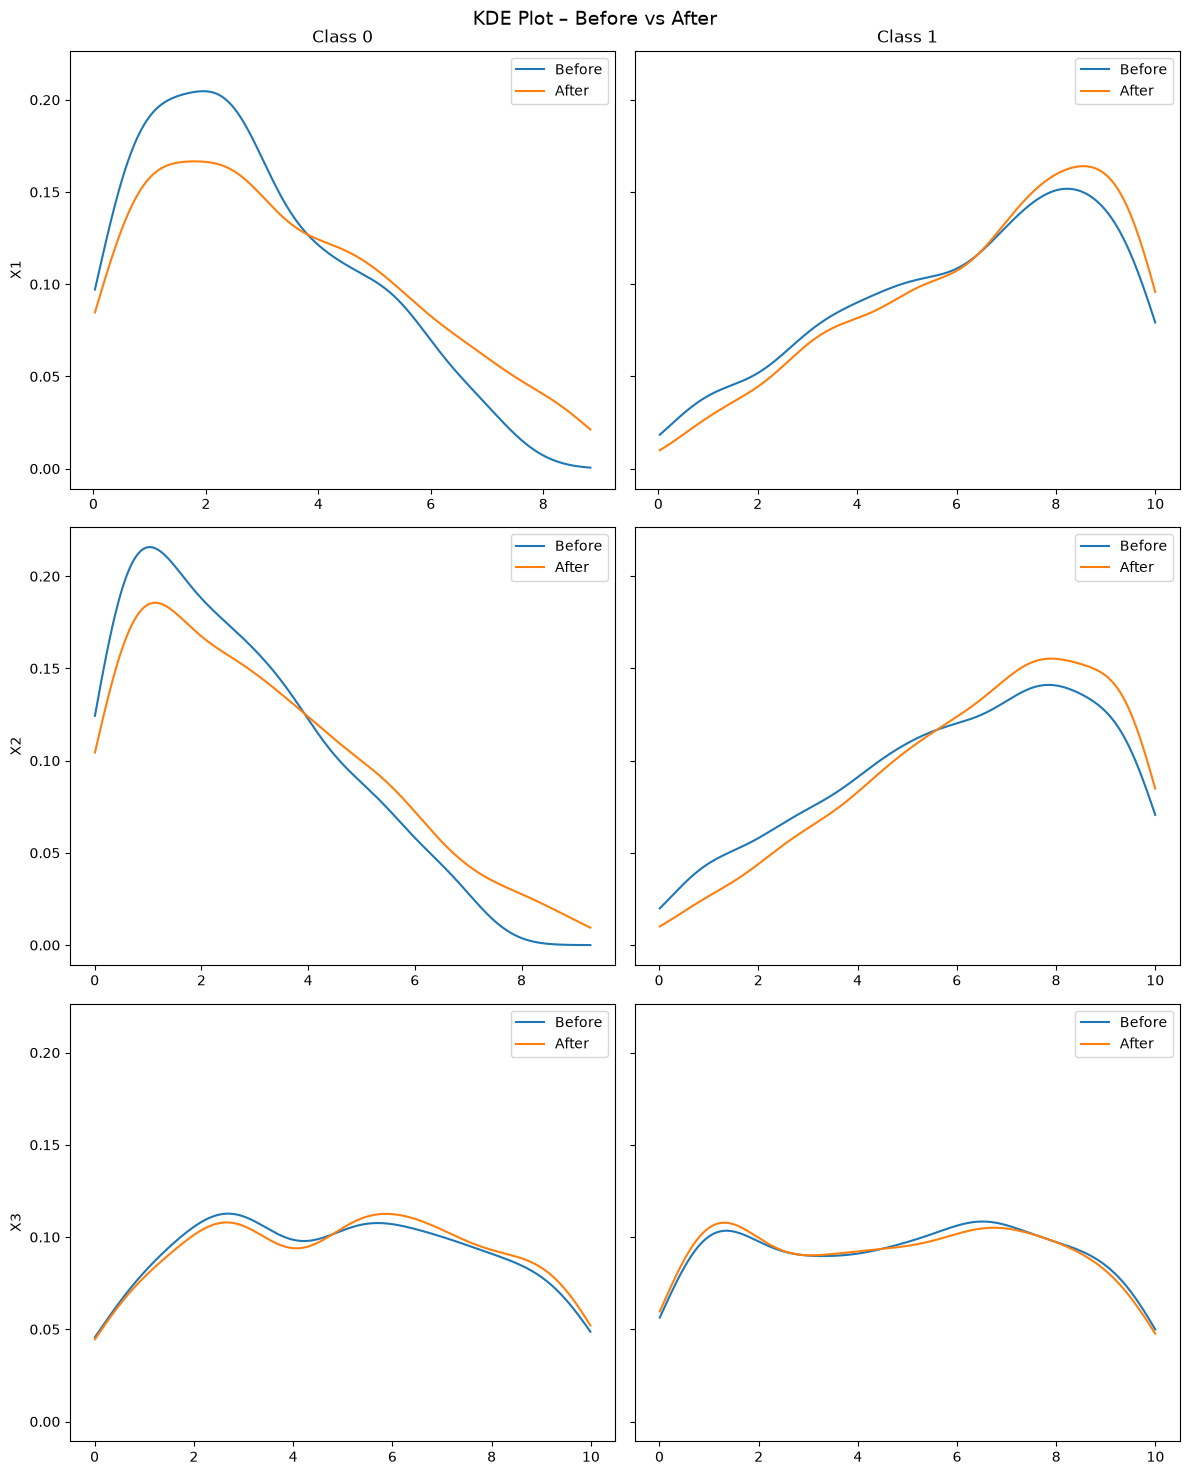

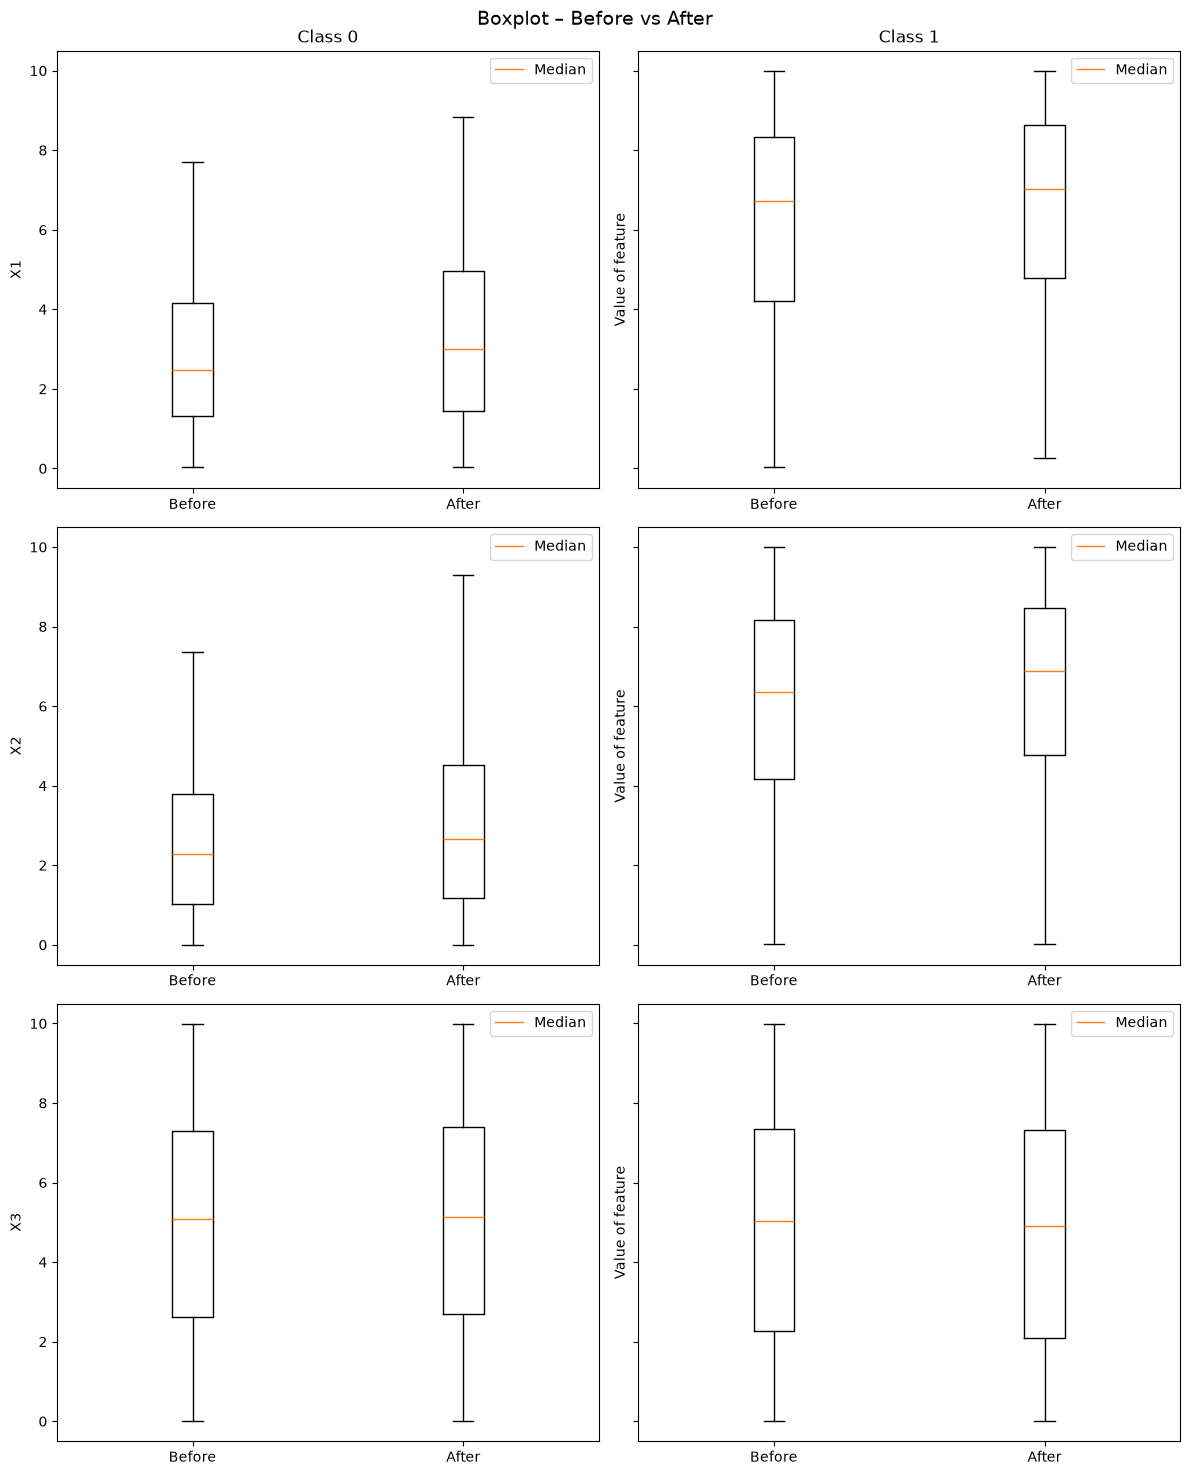

In [23]:
from stride.xai.stats import PlotOptions, plot_boxplot, plot_kde

fig_kde = plot_kde(X_ref, y_ref, X_det, y_det)
fig_box = plot_boxplot(X_ref, y_ref, X_det, y_det, show_=PlotOptions.Median)

## 2. Statistical tests

Two-sample tests and divergences on class-conditional marginals P(X | Y=y).

In [24]:
from stride.xai.stats import StatisticalTestsDriftDetector, StatisticalTestType

tests = StatisticalTestsDriftDetector(X_ref, y_ref, X_det, y_det)
print("Drift:", tests.detect(StatisticalTestType.All))
pd.Series(tests.drift_flags, name="drift")

Drift: False


kolmogorov_smirnov    False
kullback_leibler      False
wasserstein           False
jensen_shannon        False
spearman               True
anderson_darling       True
Name: drift, dtype: bool

In [25]:
# Per-test, per-class, per-feature diagnostics, e.g. Kolmogorov-Smirnov:
tests.drift_details[StatisticalTestType.KolmogorovSmirnov.value]

{False: {'X1': {'drift': True,
   'p_value': 0.02865719141827943,
   'stat': 0.1081931072758246},
  'X2': {'drift': False,
   'p_value': 0.10018469920391652,
   'stat': 0.09068765368339102},
  'X3': {'drift': False,
   'p_value': 0.9961786967601469,
   'stat': 0.02956116888022138}},
 True: {'X1': {'drift': False,
   'p_value': 0.2620734435546556,
   'stat': 0.05619878762279028},
  'X2': {'drift': False,
   'p_value': 0.08078181467418885,
   'stat': 0.07082676482346108},
  'X3': {'drift': False,
   'p_value': 0.999873827416831,
   'stat': 0.01825102896178573}}}

## 3. Clustering dynamics

X-Means inside each class, Hungarian matching of clusters across blocks, then four
criteria: cluster count, descriptive stats, centroid shift, dispersion.

In [26]:
from stride.xai.clustering import ClusterBasedDriftDetector

clus = ClusterBasedDriftDetector(X_ref, y_ref, X_det, y_det, random_state=SEED)
drift, details = clus.detect()
print("Drift:", drift, "| strength:", round(clus.strength_of_drift, 3))
print("Clusters before/after:", clus.number_of_clusters_old, "/", clus.number_of_clusters_new)
details

Drift: True | strength: 0.864
Clusters before/after: 5 / 7


{False: {'nr_of_clusters': True,
  'centroid_shift': {0: True, 1: True, 5: True},
  'desc_stats_changes': {0: {'X1': {'mean': True, 'median': True, 'std': True},
    'X2': {'mean': True, 'median': True, 'std': False},
    'X3': {'mean': False, 'median': False, 'std': False}},
   1: {'X1': {'mean': False, 'median': False, 'std': False},
    'X2': {'mean': True, 'median': True, 'std': True},
    'X3': {'mean': False, 'median': False, 'std': False}},
   5: {'X1': {'mean': True, 'median': True, 'std': True},
    'X2': {'mean': True, 'median': True, 'std': True},
    'X3': {'mean': True, 'median': True, 'std': True}}},
  'avg_distance_to_center': {0: False, 1: False, 5: True}},
 True: {'nr_of_clusters': True,
  'centroid_shift': {2: True, 3: True, 4: True, 6: True},
  'desc_stats_changes': {2: {'X1': {'mean': True,
     'median': True,
     'std': False},
    'X2': {'mean': True, 'median': True, 'std': True},
    'X3': {'mean': False, 'median': False, 'std': False}},
   3: {'X1': {'mean': F

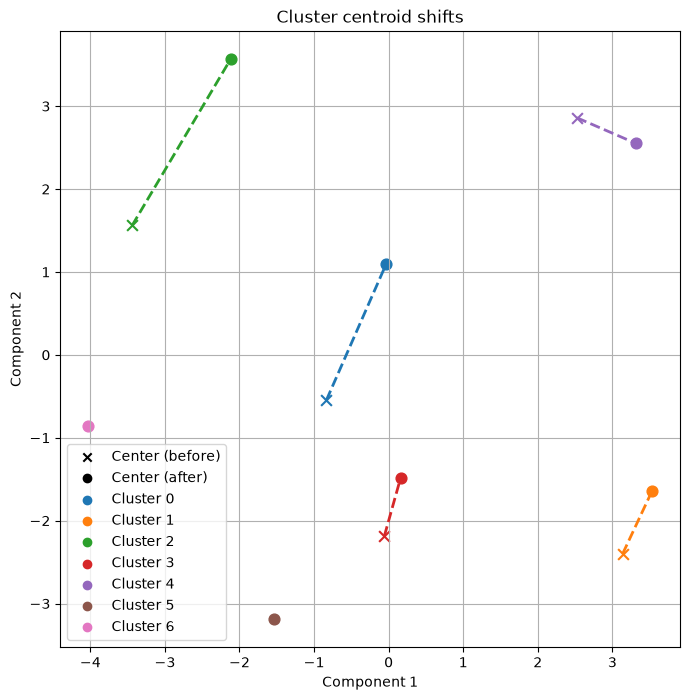

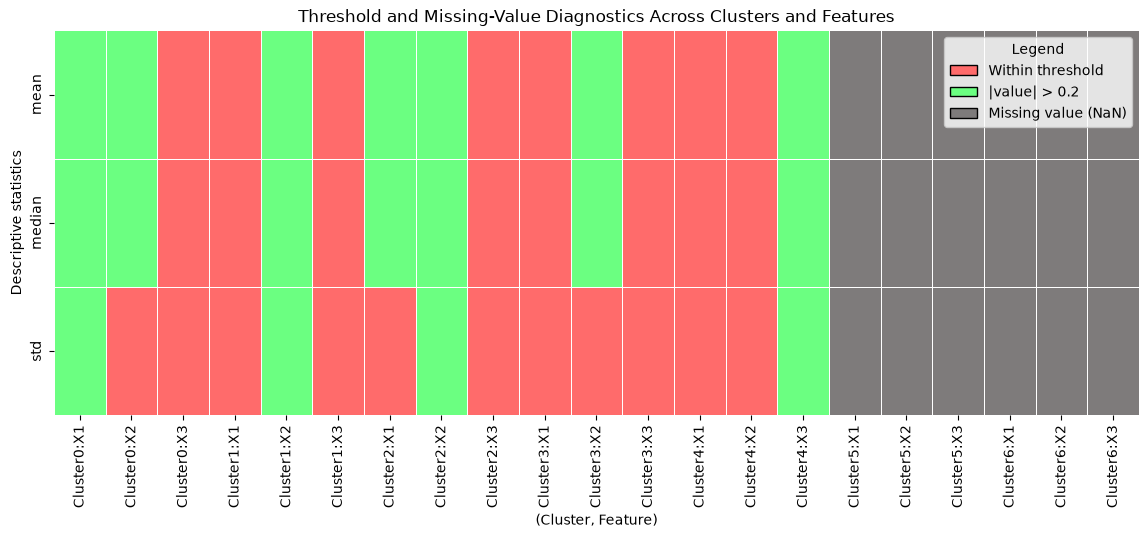

In [27]:
from stride.xai.clustering import plot_centers_shift, plot_clustering_heatmap

# Plots work in 2D; DataFrames with more columns are reduced with PCA automatically.
fig_centers = plot_centers_shift(X_ref, X_det, y_ref, y_det, clus.cluster_labels_old, clus.cluster_labels_new)
fig_heat = plot_clustering_heatmap(clus.stats_shifts, threshold=clus.thr_desc_stats)

## 4. Decision boundary shift (SDBM)

SEA has 3 features, so the analyzer fits an SSNP projection to 2D (TensorFlow),
trains one classifier per block, renders both decision maps, and fits a disagreement
tree that describes where the two classifiers disagree.

In [ ]:
from stride.models import RandomForestModel
from stride.xai.boundary import DecisionBoundaryDriftAnalyzer

db = DecisionBoundaryDriftAnalyzer(X_ref, y_ref, X_det, y_det, random_state=SEED)
with redirect_stdout(io.StringIO()):  # hide Keras progress bars printed by SSNP
    db_res = db.analyze(model_class=RandomForestModel, grid_size=150, feature_names=list(X.columns))
print("Disagreement rate on detection block:", round(db_res["disagreement"]["drift_rate"], 3))
db_res["disagreement"]["disagreement_table"]

In [ ]:
from stride.xai.boundary.visualization import plot_categorical_drift_map, visualize_decision_boundary

fig_db = visualize_decision_boundary(db_res, title="SEA: decision boundary before vs after")
with redirect_stdout(io.StringIO()):  # the drift map also calls SSNP.inverse_transform
    fig_map = plot_categorical_drift_map(
        db_res["ssnp_model"],
        db_res["disagreement"]["viz_tree"],
        db_res["disagreement"]["drift_leaf_ids"],
        db_res["post"]["grid_bounds"],
        grid_size=db_res["grid_size"],
        is_2d=db_res["is_2d"],
    )

## 5. Feature importance

Two questions, one analyzer:

* **Data-centric** (`compute_drift_importance`): train a discriminator to tell the
  reference block (t=0) from the detection block (t=1) and explain it. With
  `include_target=False` it explains covariate shift P(X); with `include_target=True`
  the label is an input too, so it captures concept drift P(Y | X).
* **Model-centric** (`compute_predictive_importance_shift`): train one classifier
  per block and compare which features each relies on to predict Y.

Methods: `"permutation"` (PFI), `"shap"`, `"lime"`.

In [ ]:
from stride.xai.importance import (
    FeatureImportanceDriftAnalyzer,
    FeatureImportanceMethod,
    visualize_drift_importance,
    visualize_predictive_importance_shift,
)

fi = FeatureImportanceDriftAnalyzer(X_ref, y_ref, X_det, y_det)
rf = dict(model_class=RandomForestModel, model_params={"random_state": SEED})

rows = {}
with redirect_stderr(io.StringIO()):  # hide SHAP's tqdm progress bar
    for include_target in (False, True):
        for method in FeatureImportanceMethod.all_available():
            res = fi.compute_drift_importance(importance_method=method, include_target=include_target, **rf)
            rows[("P(Y|X)" if include_target else "P(X)", method)] = dict(
                zip(res["feature_names"], res["importance_mean"]), discriminator_acc=res["accuracy"]
            )
pd.DataFrame(rows).T.round(3)

In [ ]:
# Concept-drift attribution with PFI, plotted
res = fi.compute_drift_importance(importance_method="permutation", include_target=True, **rf)
fig_fi = visualize_drift_importance(res, res["feature_names"], plot_type="bar", include_target=True)

**Selective localization.** With an abstention strategy, the analyzer keeps only the
samples the discriminator is confident about (the drift locus) and explains those.

In [ ]:
from stride.xai.importance import AbstainStrategy

for strategy in AbstainStrategy.all_available():
    res = fi.compute_drift_importance(importance_method="permutation", include_target=True, abstain_strategy=strategy, **rf)
    print(
        f"{strategy:22s} coverage={res['drift_coverage']:.2f} "
        f"selective_acc={res['selective_accuracy']:.2f} fallback={res['drift_locus_fallback']} "
        f"importance={dict(zip(res['feature_names'], res['importance_mean'].round(3)))}"
    )

In [ ]:
shift = fi.compute_predictive_importance_shift(importance_method="permutation", **rf)
print("Accuracy before/after:", round(shift["accuracy_before"], 3), "/", round(shift["accuracy_after"], 3))
fig_shift = visualize_predictive_importance_shift(shift, list(X.columns), plot_type="bar")

# Longer Data: RandomTree

In [28]:
from stride.datasets import RandomTreeMultiWindowDataset

DRIFTS = [10 * BLOCK, 20 * BLOCK]
X_s, y_s = RandomTreeMultiWindowDataset().generate(
    num_windows=30, window_length=BLOCK, drift_positions=DRIFTS, random_seed=SEED
)

## 6. Recurring concepts (prototypes)

Split a long stream into 1000-sample windows, select class prototypes per window
with an online model, compute a window-to-window distance matrix and cluster it.
Windows in the same cluster are similar to each other, so they share a concept.
If a concept reappears after it was replaced with a different concept, it is a recurring concept.

This section uses `RandomTreeMultiWindowDataset` instead of SEA: its concept flips at
each drift position, so drifts at windows 10 and 20 give the pattern A, B, A.

In [29]:
from river import forest


from stride.xai.recurrence import FullWindowStorage, cluster_windows, get_drift_from_clusters
from stride.xai.recurrence.methods import create_prototypes_for_stream, prepare_dataset_from_generator

windows = prepare_dataset_from_generator(X_s, y_s, window_size=BLOCK)

storage = FullWindowStorage()
create_prototypes_for_stream(forest.ARFClassifier(seed=SEED), storage, windows, verbose=False)
print(len(storage.get_all_iterations()), "windows stored")

30 windows stored


In [30]:
dist_matrix = storage.compute_distance_matrix(measure="centroid_displacement")
labels = cluster_windows(dist_matrix)
print("Cluster per window:", labels.tolist())
drifts = get_drift_from_clusters(labels)
print("Detected drift windows:", drifts, "| true drift windows:", [d // BLOCK for d in DRIFTS])

Cluster per window: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Detected drift windows: [10, 20] | true drift windows: [10, 20]


Here we display the **distance matrix**, which shows which windows are similar

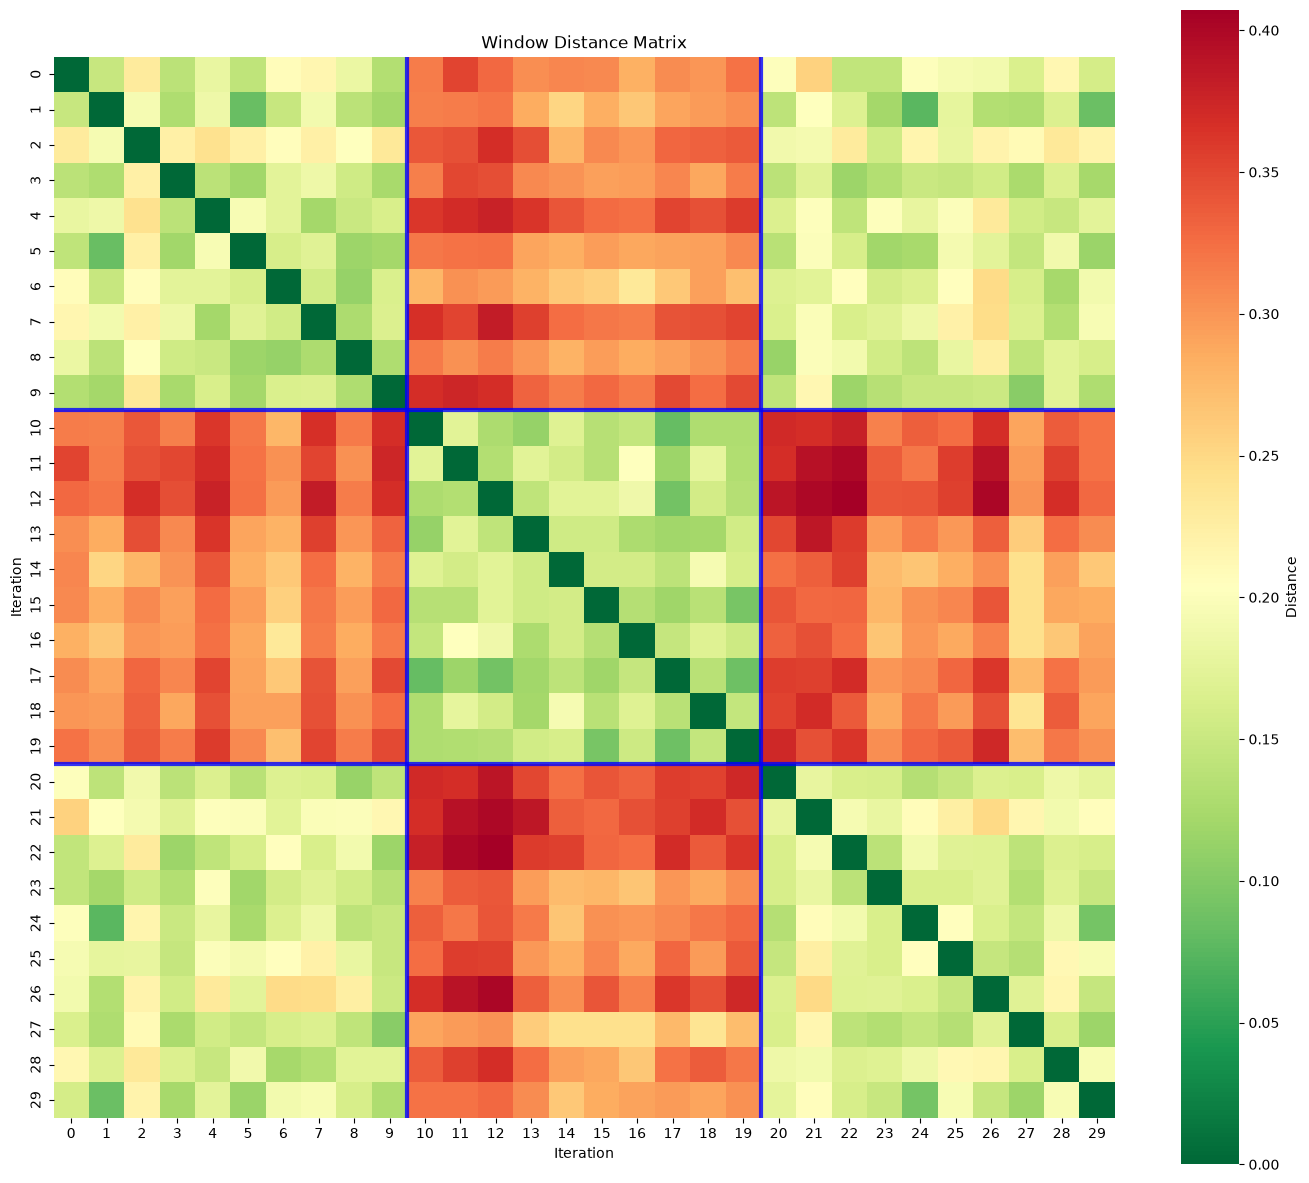

In [31]:
from stride.xai.recurrence.visualization import plot_prototype_comparison, visualize_distance_matrix, plot_cluster_timeline

fig_dist = visualize_distance_matrix(dist_matrix, drift_positions=drifts)

The evolution of concept can be shown on a plot

In [32]:
plot_cluster_timeline(labels, drift_locations=drifts)

The **prototypes** can be displayed 

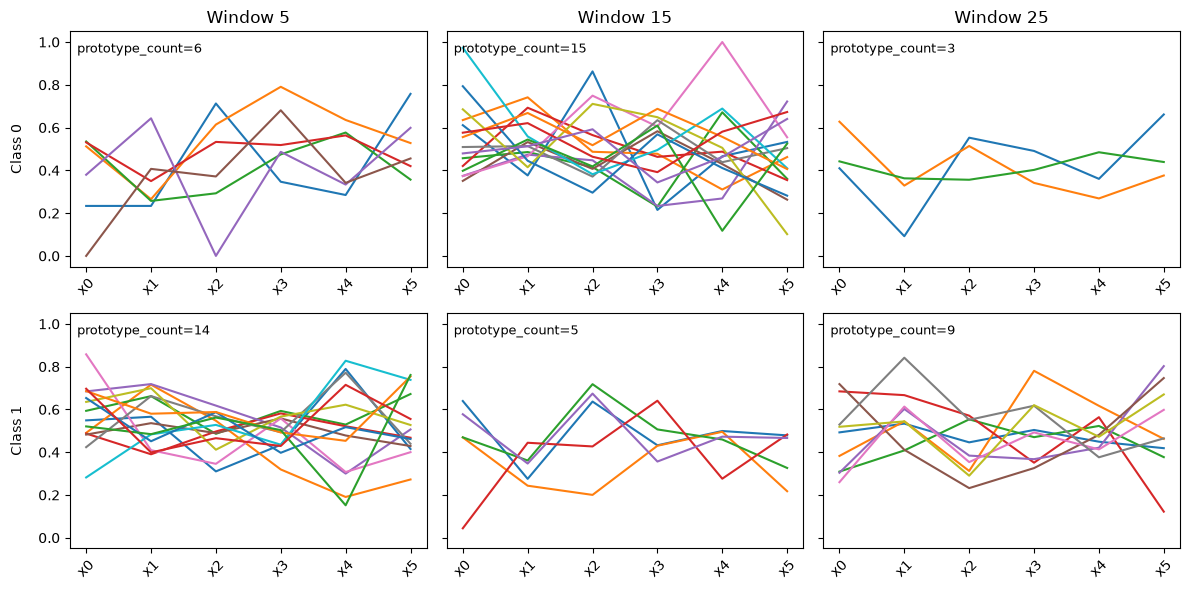

In [33]:
fig_protos = plot_prototype_comparison(storage, windows_to_compare=[5, 15, 25])

If you want to access the **prototypes** directly, you can do so using **storage**

They are stored as a dict of windows, numbered from 0. Each window is a dict of classes. Each class is a list of prototypes of that class. Each prototype is a dict of features and values.

In [34]:
storage.prototypes

{0: {0: [{'x0': 0.3983188090212495,
    'x1': 0.2516318966588933,
    'x2': 0.5367023646175471,
    'x3': 0.5706315246445332,
    'x4': 0.6063833784437692,
    'x5': 0.6392702253304975},
   {'x0': 0.6109880399134675,
    'x1': 0.21028203949675167,
    'x2': 0.706048042574055,
    'x3': 0.43327508964119,
    'x4': 0.3342144773990209,
    'x5': 0.37565968875222244},
   {'x0': 0.0,
    'x1': 0.5847346397499127,
    'x2': 0.22341300993664376,
    'x3': 0.2638193096858389,
    'x4': 0.29860534563961705,
    'x5': 0.43745683999652474},
   {'x0': 0.4463878157015775,
    'x1': 0.2048418204300605,
    'x2': 0.544800626666306,
    'x3': 0.7822010414647234,
    'x4': 0.7503380733519185,
    'x5': 0.647925228800975},
   {'x0': 0.3951427861145586,
    'x1': 0.30803719887099124,
    'x2': 0.649881422955016,
    'x3': 0.5043504368031921,
    'x4': 0.12927929660767074,
    'x5': 0.5404330755415786}],
  1: [{'x0': 0.5384180761265298,
    'x1': 0.8194225445041622,
    'x2': 0.449416139178601,
    'x3': 

In [35]:
#[window nr][class label][index of prototype in list]
storage.prototypes[0][0][0]

{'x0': 0.3983188090212495,
 'x1': 0.2516318966588933,
 'x2': 0.5367023646175471,
 'x3': 0.5706315246445332,
 'x4': 0.6063833784437692,
 'x5': 0.6392702253304975}

# 7. Error rate based drift detection (DDM & ADWIN)

This method processes the enitre stream without dividing it into blocks.

First an online learning model is trained on the data and based on its predictions an error stream is created. 1 means error 0 means no error from the predictor on a given sample.

The error stream is used by the BinaryErrorDriftDescriptor to detect and describe drifts.

There are several detectors that might be used: "ADWIN", "DDM", "EDDM", "FHDDM", "HDDM_A", "HDDM_W"

After a drift is detected, it is described to determine the point at which the drift begins and ends as well as the error rate at those points. Methods wich will be used to find said points can be chosen from the selection below.

lookback method: 'cusum', 'threshold', 'gradient', 'none'

lookforward method: 'peak', 'recovery', 'none'

In [36]:
from stride.drift.binary_descriptor import generate_error_stream, run_drift_detection, visualization_and_correction

import numpy as np
from sklearn.neural_network import MLPClassifier

detector = "DDM"
lookback_method = "gradient"
lookforward_method = 'recovery'

rate_calculation_sample_size = 100 # Determines the size of the pooling window for error rate calculation
visualize = True


model = MLPClassifier(
    hidden_layer_sizes=(3,),
    max_iter=1,
    random_state=42
)

X_np = X_s.to_numpy() if hasattr(X_s, "to_numpy") else X_s
y_np = y_s.to_numpy() if hasattr(y_s, "to_numpy") else y_s

error_stream, predictions = generate_error_stream(X_np, y_np, model)
error_array = np.array(error_stream)
error_rate = [
    np.mean(error_array[i:i + rate_calculation_sample_size])
    for i in range(len(error_stream) - rate_calculation_sample_size + 1)
]

drift_descriptions = run_drift_detection(error_stream, detector, 1, rate_calculation_sample_size, lookback_method, lookforward_method)
corrected_descriptions = visualization_and_correction(drift_descriptions, error_rate, rate_calculation_sample_size, visualize)
corrected_descriptions

[{'start': 10059,
  'end': 10100,
  'duration': 41,
  'start_error_rate': 0.59,
  'end_error_rate': 0.87,
  'error_rate_increase': 0.28},
 {'start': 20078,
  'end': 20103,
  'duration': 25,
  'start_error_rate': 0.72,
  'end_error_rate': 0.92,
  'error_rate_increase': 0.20000000000000007}]